In [6]:
import pandas as pd

In [7]:
df = pd.read_csv("performance_data_time.csv")

In [8]:
df.columns

Index(['Query #', 'Type', 'Query', 'Table(s)', 'Rows Returned',
       'Columns Returned', 'Execution Time (s)', 'CPU Used (%)',
       'RAM Used (MB)', 'Disk Read (MB)', 'Error'],
      dtype='str')

## Exploratory Data Analysis (EDA)

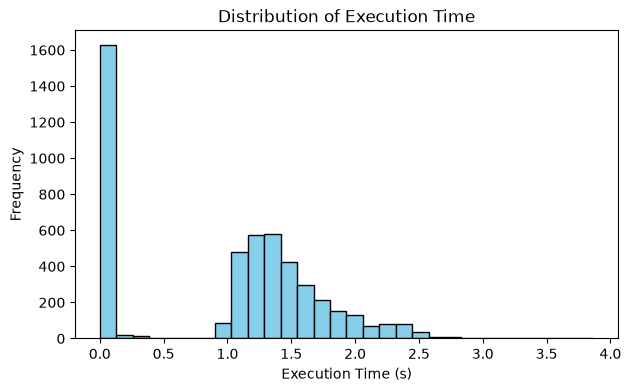

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(df['Execution Time (s)'].dropna(), bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Execution Time')
plt.xlabel('Execution Time (s)')
plt.ylabel('Frequency')
plt.show()

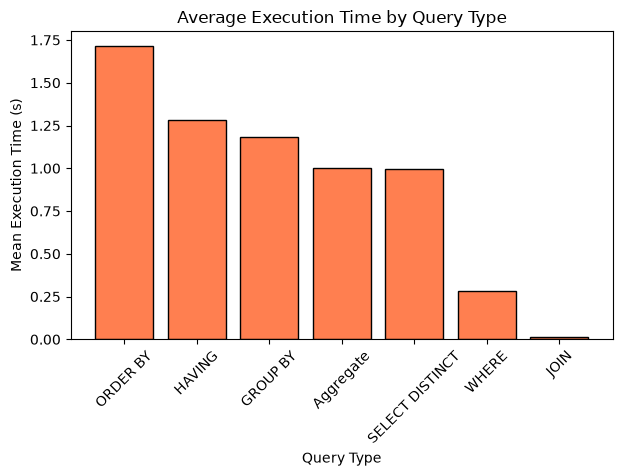

In [10]:
avg_type = df.groupby('Type')['Execution Time (s)'].mean().sort_values(ascending=False)

plt.figure(figsize=(7, 4))
plt.bar(avg_type.index, avg_type.values, color='coral', edgecolor='black')
plt.title('Average Execution Time by Query Type')
plt.xlabel('Query Type')
plt.ylabel('Mean Execution Time (s)')
plt.xticks(rotation=45)
plt.show()

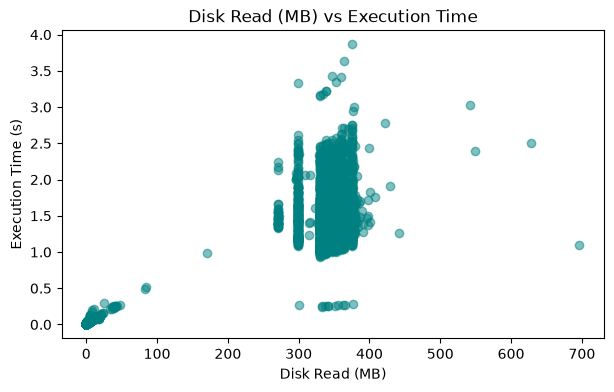

In [11]:
plt.figure(figsize=(7, 4))
plt.scatter(df['Disk Read (MB)'], df['Execution Time (s)'], alpha=0.5, color='teal')
plt.title('Disk Read (MB) vs Execution Time')
plt.xlabel('Disk Read (MB)')
plt.ylabel('Execution Time (s)')
plt.show()

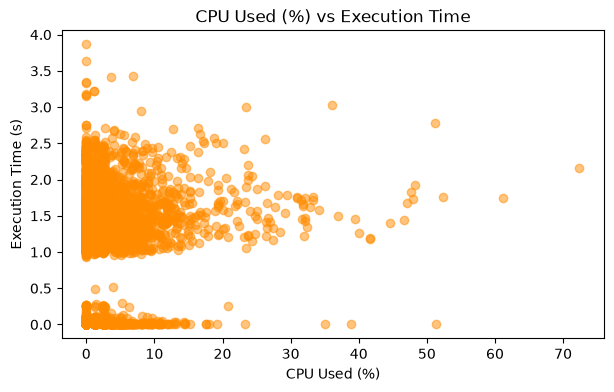

In [12]:
plt.figure(figsize=(7, 4))
plt.scatter(df['CPU Used (%)'], df['Execution Time (s)'], alpha=0.5, color='darkorange')
plt.title('CPU Used (%) vs Execution Time')
plt.xlabel('CPU Used (%)')
plt.ylabel('Execution Time (s)')
plt.show()

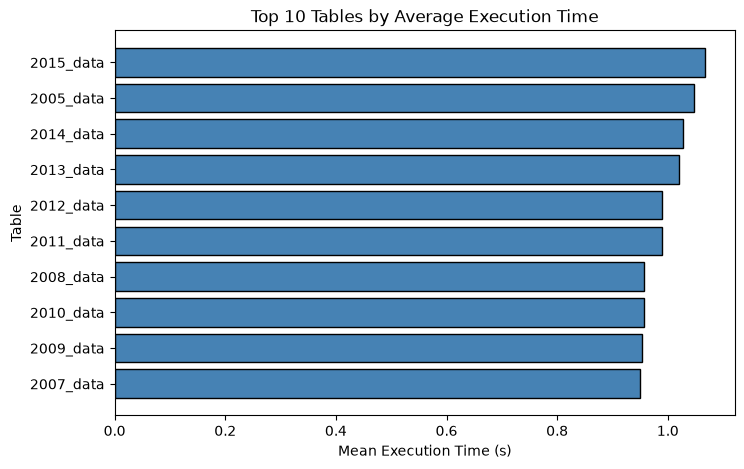

In [13]:
top_tables = df.groupby('Table(s)')['Execution Time (s)'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
plt.barh(top_tables.index[::-1], top_tables.values[::-1], color='steelblue', edgecolor='black')
plt.title('Top 10 Tables by Average Execution Time')
plt.xlabel('Mean Execution Time (s)')
plt.ylabel('Table')
plt.show()

## Model Building (Regression Pipeline)

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [15]:
num_cols = ['Rows Returned', 'Columns Returned', 'CPU Used (%)', 'RAM Used (MB)', 'Disk Read (MB)']
cat_cols = ['Type', 'Table(s)']

X = df[num_cols + cat_cols]
y = df['Execution Time (s)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [17]:
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Rows Returned','Columns Returned','CPU Used (%)',...,'Disk Read (MB)', 'Type','Table(s)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. 

In [18]:
y_pred = model_pipeline.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("Root Mean Squared Error (RMSE):", mean_squared_error(y_test, y_pred) ** 0.5)

R2 Score: 0.968329284876876
Mean Absolute Error (MAE): 0.07129114949043182
Root Mean Squared Error (RMSE): 0.13835917128077443


In [19]:
import joblib


joblib.dump(model_pipeline, 'database_time_model.pkl')
print("Model exported successfully as 'database_time_model.pkl'!")

Model exported successfully as 'database_time_model.pkl'!
